# AP 155 Lab Exercise
---
## Exercise 8: Minimization

_Instructions_: 
- **Report figure:** A 2 by 2 figure plot. Upper row contains the plot of the actual functions. Lower row contains a plot of their derivatives. Use markers to plot the found local extrema by the golden section search algorithm.  
- **Report discussion:** What happens if a number other than the golden ratio is used to perform the *golden* section search algorithm?
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Maribao, Jake Agustin
- _Student No._: 2023-08777
- _Section_: THR-TX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view?usp=sharing) (Note: percentages may still be tweaked)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_:_

---
## Section 1: Report

### Report figure

![Extrema of Eq. 5.91 & Eq. 5.145](minimization.png)

**Report figure.** Top row: Eq. 5.91, $\phi(x) = x^4 - 9x^3 + 25x^2 - 24x + 4$ (left),
and Eq. 5.145, $f(x) = (x-2)^2(e^x - x^3 - 2)$ in expanded form (right). Bottom row: their
analytic derivatives. Markers are the extrema found by golden-section search: green circles for
minima, red circles for maxima, labelled with $(x^*, \phi(x^*))$; dotted lines carry each $x^*$
down to the derivative panel, where every marker sits on $\phi'(x) = 0$. Eq. 5.91 has minima
at $x = 0.75$ and $x = 4$ (the global minimum, $-12$) and a maximum at $x = 2$. Eq. 5.145 has
minima at $x \approx -0.680$ and $x \approx 4.103$ and a maximum at its double root $x = 2$. The
right column is cropped vertically; the flat stretch of $f$ near $x \approx 1.2$, where $f'$
nearly touches zero, is not an extremum because $f'$ stays positive there.

### Report discussion

**What happens if a number other than the golden ratio is used to perform the *golden* section search algorithm?**

For any ratio $r > 1$ the search still converges: both outcomes leave the same fraction
$r/(r+1)$ of the interval, so Eq. 5.93 holds. What is lost is
Eq. 5.94: only for $r = \varphi$ does the surviving interior point land exactly where the next
step needs one, so it can be reused and each step costs one evaluation, shrinking the
interval by $1/\varphi \approx 0.618$ per evaluation. Other ratios recompute both points, giving
at best $\sqrt{r/(r+1)} \approx 0.707$ per evaluation. On $\phi$ over
$(3, 5)$ the golden ratio needed 42 evaluations, $r = 1.01$ needed 58, $r = 2$ needed 98,
$r = 5$ needed 212, and $r = 10$ did not converge in 200 iterations. Ratios near 1 also crowd the
two points so that roundoff decides the comparison. A
ratio $r \le 1$ swaps $x_2$ and $x_3$, and the update discards the half holding the minimum.

### Other comments
- Golden-section search only minimises, so each maximum was found by minimising the
  negated function on a bracket around the peak.
- At the maximum of Eq. 5.145 (its double root), tightening the tolerance below $10^{-8}$ did
  not improve the answer: the error stalled near $7\times10^{-9}$. Near any extremum the
  function is quadratic, so points closer than roughly $\sqrt{\varepsilon_{\text{mach}}}$
  give values floating point cannot tell apart. This limits every minimiser that uses only
  function values.
- The estimates in Gezerlis 5.5.1 (minimum near $0.7$, maximum at $2$, minimum near $4$
  for Eq. 5.91) match the exact factorisation $\phi'(x) = (x-2)(4x^2 - 19x + 12)$.


---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

### Problem 1: Minimization

Consider the following equations:

Eq. 5.91
$$
\phi(x) = x^4 - 9x^3 + 25x^2 - 24x + 4
$$

Eq. 5.145
$$
f(x) = -x^5 + 4x^4 - 4x^3 + x^2 e^x - 2x^2 - 4xe^x + 8x + 4e^x - 8
$$


1. Plot each of the functions. Get a rough estimate of the local minima and maxima
2. Implement 5.5.2.2 (golden section search), then determine the local minima and maxima of Eq. 5.91 and Eq. 5.145.
3. Report figure: A 2 by 2 figure plot. Upper row contains the plot of the actual functions. Lower row contains a plot of their derivatives. Use markers to plot the found local extrema by the golden section search algorithm. 

**Problem 1 notes**

*Rough estimates (item 1).* From the plots below: Eq. 5.91 has a minimum near $0.7$, a
maximum at $2$ and a deeper minimum near $4$; Eq. 5.145 on $[-2, 5]$ has a minimum near
$-0.7$, a maximum at $2$ (its double root) and a minimum near $4.1$. Factorising confirms
these: $\phi'(x) = (x-2)(4x^2 - 19x + 12)$ vanishes exactly at $0.75$, $2$ and $4$, and
$f(x) = (x-2)^2(e^x - x^3 - 2)$ has a stationary point at $2$ because of the squared
factor. The flat shoulder of $f$ near $x \approx 1.2$ is not an extremum: $f'$ dips to
about $0.012$ there but stays positive.

*Golden-section search (Gezerlis 5.5.2.2).* Start from a bracket $(x_0, x_1)$ that holds one
minimum. Place two interior points by Eq. 5.97,
$x_2 = x_0 + \frac{x_1 - x_0}{\varphi + 1}$ and $x_3 = x_0 + \frac{(x_1 - x_0)\,\varphi}{\varphi + 1}$.
If $\phi(x_3) < \phi(x_2)$ the minimum is in $(x_2, x_1)$, so $x_0 \leftarrow x_2$; otherwise it
is in $(x_0, x_3)$, so $x_1 \leftarrow x_3$. Stop when $|x_1 - x_0| <$ tol and return the
midpoint. Code 5.6 recomputes both interior points every step; here the surviving interior
point is reused, because with the golden ratio it lands exactly where the next step needs one
(Problem 5.25). That halves the cost to one new evaluation per step. For any other ratio the
reuse would put the point in the wrong place, so both points are recomputed as in Code 5.6.

*Maxima.* The method only minimises, so each maximum is found by minimising $-\phi$ on a
bracket around the peak. Each result is checked independently with the analytic
derivatives: $\phi'(x^*) \approx 0$ confirms a stationary point, and the sign of
$\phi''(x^*)$ confirms whether it is a minimum or a maximum.

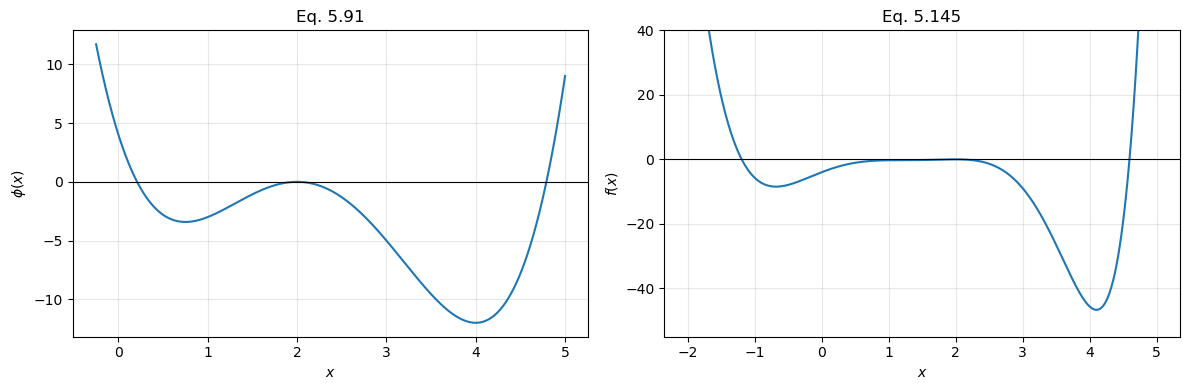

In [2]:
def phi(x):
    """Eq. 5.91: x^4 - 9x^3 + 25x^2 - 24x + 4."""
    return x**4 - 9*x**3 + 25*x**2 - 24*x + 4


def phi_prime(x):
    """First derivative of Eq. 5.91, equal to (x - 2)(4x^2 - 19x + 12)."""
    return 4*x**3 - 27*x**2 + 50*x - 24


def phi_second(x):
    """Second derivative of Eq. 5.91, used to classify extrema."""
    return 12*x**2 - 54*x + 50


def f(x):
    """Eq. 5.145: -x^5 + 4x^4 - 4x^3 + x^2 e^x - 2x^2 - 4x e^x + 8x + 4e^x - 8."""
    return (-x**5 + 4*x**4 - 4*x**3 + x**2*np.exp(x) - 2*x**2
            - 4*x*np.exp(x) + 8*x + 4*np.exp(x) - 8)


def f_prime(x):
    """First derivative of Eq. 5.145."""
    return -5*x**4 + 16*x**3 - 12*x**2 - 4*x + 8 + np.exp(x)*(x**2 - 2*x)


def f_second(x):
    """Second derivative of Eq. 5.145, used to classify extrema."""
    return -20*x**3 + 48*x**2 - 24*x - 4 + np.exp(x)*(x**2 - 2)


# Item 1: plot of both functions to estimate where the extrema are.
x_phi = np.linspace(-0.25, 5.0, 1001)
x_f = np.linspace(-2.0, 5.0, 1401)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(x_phi, phi(x_phi))
ax1.set_title(r'Eq. 5.91')
ax1.set_ylabel(r'$\phi(x)$')
ax2.plot(x_f, f(x_f))
ax2.set_ylim(-55, 40)            # f reaches about 190 at x = 5, so crop to see the extrema
ax2.set_title(r'Eq. 5.145')
ax2.set_ylabel(r'$f(x)$')
for ax in (ax1, ax2):
    ax.axhline(0, color='k', lw=0.8)
    ax.set_xlabel('$x$')
    ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig('plot_of_phi(x)_f(x)')

In [3]:
GOLDEN = 0.5*(1 + math.sqrt(5))


def golden(phi, x0, x1, ratio=GOLDEN, tol=1e-8, kmax=200):
    """Golden-section search for a minimum of phi bracketed by (x0, x1), Gezerlis 5.5.2.2.

    phi : function of one variable. x0, x1 : bracket containing one minimum.
    ratio : big-to-small subinterval ratio B/S (Eq. 5.96); must exceed 1.
    Returns the midpoint of the final interval, a float.

    Interior points follow Eq. 5.97. If phi(x3) < phi(x2) the minimum lies in
    (x2, x1), otherwise in (x0, x3). With the golden ratio the surviving interior
    point is exactly one of the next pair, so it is reused and each step costs
    one new evaluation (Problem 5.25). Any other ratio recomputes both points,
    as in Code 5.6.
    """
    if ratio <= 1:
        raise ValueError(f"ratio must exceed 1 so that x2 < x3, got {ratio}")
    reuse = math.isclose(ratio, GOLDEN)
    x2 = x0 + (x1 - x0)/(ratio + 1)
    x3 = x0 + (x1 - x0)*ratio/(ratio + 1)
    p2, p3 = phi(x2), phi(x3)
    for _ in range(kmax):
        if p3 < p2:                              # minimum in (x2, x1)
            x0 = x2
            if reuse:
                x2, p2 = x3, p3
            else:
                x2 = x0 + (x1 - x0)/(ratio + 1)
                p2 = phi(x2)
            x3 = x0 + (x1 - x0)*ratio/(ratio + 1)
            p3 = phi(x3)
        else:                                    # minimum in (x0, x3)
            x1 = x3
            if reuse:
                x3, p3 = x2, p2
            else:
                x3 = x0 + (x1 - x0)*ratio/(ratio + 1)
                p3 = phi(x3)
            x2 = x0 + (x1 - x0)/(ratio + 1)
            p2 = phi(x2)
        if abs(x1 - x0) < tol:
            return (x0 + x1)/2
    raise RuntimeError(f"golden did not converge in {kmax} iterations")


def counted(func):
    """Wrap func so that wrapper.calls records how many times it was evaluated."""
    def wrapper(x):
        wrapper.calls += 1
        return func(x)
    wrapper.calls = 0
    return wrapper

In [4]:
# Item 2: one bracket per extremum, read off the plots above.
searches = [
    # label           function  derivative  2nd deriv. attribute   bracket
    ('Eq. 5.91',      phi,      phi_prime,  phi_second,  'min', (0.0, 1.5)),
    ('Eq. 5.91',      phi,      phi_prime,  phi_second,  'max', (1.5, 3.0)),
    ('Eq. 5.91',      phi,      phi_prime,  phi_second,  'min', (3.0, 5.0)),
    ('Eq. 5.145',     f,        f_prime,    f_second,    'min', (-1.5, 0.5)),
    ('Eq. 5.145',     f,        f_prime,    f_second,    'max', (1.5, 3.0)),
    ('Eq. 5.145',     f,        f_prime,    f_second,    'min', (3.0, 5.0)),
]

extrema = []    # (label, attribute, x*, value) for the report figure
print(f"{'function':10s} {'attribute':>9s} {'bracket':>13s} {'x*':>14s} {'value':>11s} "
      f"{'derivative':>11s} {'2nd deriv.':>11s} {'evals':>6s}")
for label, func, deriv, deriv2, attribute, (a, b) in searches:
    target = counted(func if attribute == 'min' else (lambda x, g=func: -g(x)))
    x_star = golden(target, a, b)
    extrema.append((label, attribute, x_star, func(x_star)))
    print(f"{label:10s} {attribute:>9s} {f'({a}, {b})':>13s} {x_star:14.10f} {func(x_star):11.6f} "
          f"{deriv(x_star):11.1e} {deriv2(x_star):+11.4f} {target.calls:6d}")

function   attribute       bracket             x*       value  derivative  2nd deriv.  evals
Eq. 5.91         min    (0.0, 1.5)   0.7500000045   -3.417969     7.4e-08    +16.2500     42
Eq. 5.91         max    (1.5, 3.0)   1.9999999627   -0.000000     3.7e-07    -10.0000     42
Eq. 5.91         min    (3.0, 5.0)   3.9999999940  -12.000000    -1.6e-07    +26.0000     42
Eq. 5.145        min   (-1.5, 0.5)  -0.6798620150   -8.467698    -2.9e-07    +40.0085     42
Eq. 5.145        max    (1.5, 3.0)   1.9999999945   -0.000000     2.9e-08     -5.2219     42
Eq. 5.145        min    (3.0, 5.0)   4.1033248615  -46.662165    -6.2e-07   +222.2003     42


In [5]:
# Discussion experiment: the same search on phi over (3, 5), true minimum x = 4,
# with ratios other than the golden ratio.
print(f"{'ratio':>8s} {'shrink/step':>12s} {'evals':>6s} {'shrink/eval':>12s} {'x*':>14s} {'error':>9s}")
for r in [1.01, 1.2, 1.5, GOLDEN, 2.0, 3.0, 5.0, 10.0]:
    counter = counted(phi)
    per_eval = r/(r + 1) if math.isclose(r, GOLDEN) else math.sqrt(r/(r + 1))
    try:
        x_star = golden(counter, 3.0, 5.0, ratio=r)
        print(f"{r:8.4f} {r/(r + 1):12.4f} {counter.calls:6d} {per_eval:12.4f} {x_star:14.10f} {abs(x_star - 4):9.1e}")
    except RuntimeError as err:
        print(f"{r:8.4f} {r/(r + 1):12.4f} {counter.calls:6d} {per_eval:12.4f}   {err}")

   ratio  shrink/step  evals  shrink/eval             x*     error
  1.0100       0.5025     58       0.7089   3.9999995861   4.1e-07
  1.2000       0.5455     66       0.7385   4.0000000830   8.3e-08
  1.5000       0.6000     78       0.7746   3.9999999743   2.6e-08
  1.6180       0.6180     42       0.6180   3.9999999940   6.0e-09
  2.0000       0.6667     98       0.8165   3.9999999805   1.9e-08
  3.0000       0.7500    136       0.8660   3.9999999923   7.7e-09
  5.0000       0.8333    212       0.9129   3.9999999850   1.5e-08
 10.0000       0.9091    402       0.9535   golden did not converge in 200 iterations


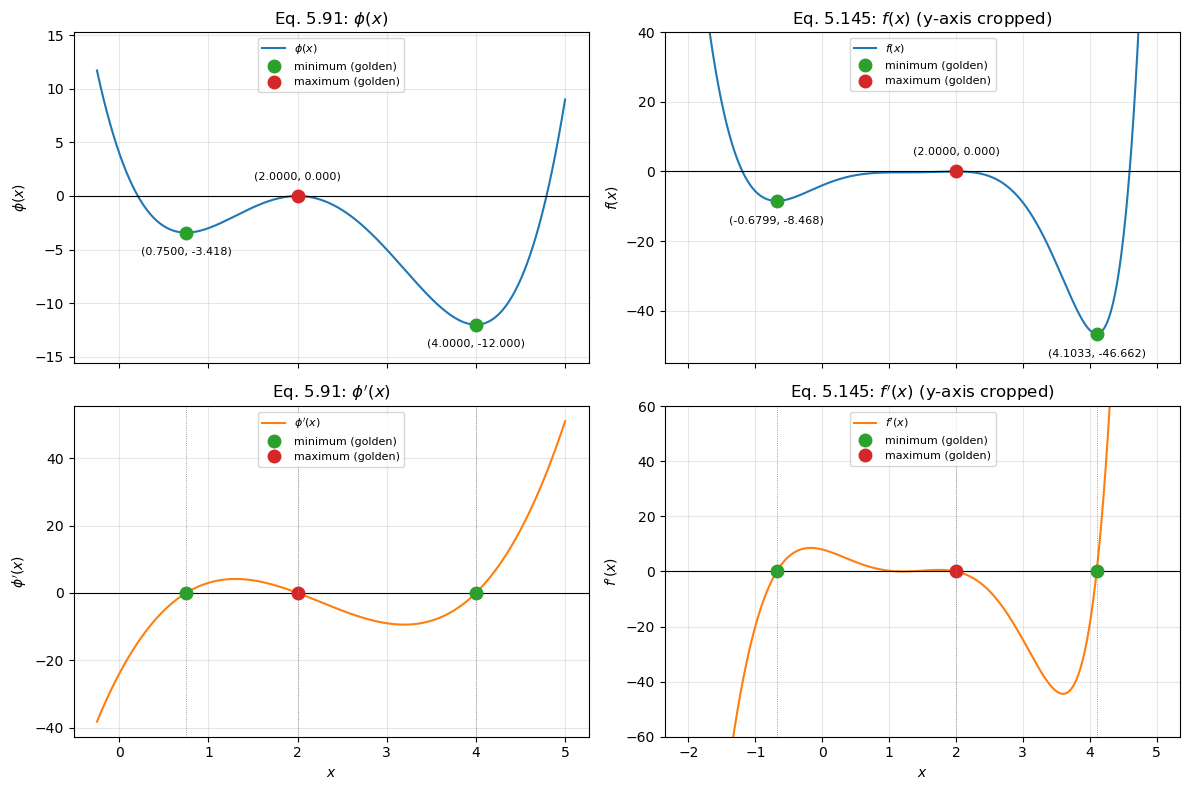

In [6]:
# REPORT FIGURE: functions (top) and derivatives (bottom), extrema from golden()
panels = [('Eq. 5.91', r'\phi', phi, phi_prime, x_phi, None, None),
          ('Eq. 5.145', 'f', f, f_prime, x_f, (-55, 40), (-60, 60))]
style = {'min': dict(marker='o', color='C2', label='minimum (golden)'),
         'max': dict(marker='o', color='C3', label='maximum (golden)')}

fig, axs = plt.subplots(2, 2, figsize=(12, 8), sharex='col')
for col, (label, sym, func, deriv, xs, ylim_f, ylim_d) in enumerate(panels):
    ax_f, ax_d = axs[0, col], axs[1, col]
    ax_f.plot(xs, func(xs), color='C0', lw=1.5, label=f'${sym}(x)$')
    ax_d.plot(xs, deriv(xs), color='C1', lw=1.5, label=f"${sym}'(x)$")
    for ax in (ax_f, ax_d):
        ax.axhline(0, color='k', lw=0.8)
        ax.grid(alpha=0.3)
    for name, attribute, x_star, value in extrema:
        if name != label:
            continue
        ax_f.plot(x_star, value, ls='none', ms=9, **style[attribute])
        shown = value if abs(value) >= 5e-4 else 0.0     # avoid printing -0.000 at the maxima
        ax_f.annotate(f'({x_star:.4f}, {shown:.3f})', (x_star, value), textcoords='offset points',
                      xytext=(0, 12 if attribute == 'max' else -16), ha='center', fontsize=8)
        ax_d.plot(x_star, deriv(x_star), ls='none', ms=9, **style[attribute])
        ax_d.axvline(x_star, color='gray', lw=0.6, ls=':')
    if ylim_f:
        ax_f.set_ylim(*ylim_f)
        ax_d.set_ylim(*ylim_d)
    else:
        ax_f.margins(y=0.15)                        # room for the annotations
    ax_f.set_title(f'{label}: ${sym}(x)$' + (' (y-axis cropped)' if ylim_f else ''))
    ax_d.set_title(f"{label}: ${sym}'(x)$" + (' (y-axis cropped)' if ylim_d else ''))
    ax_f.set_ylabel(f'${sym}(x)$')
    ax_d.set_ylabel(f"${sym}'(x)$")
    ax_d.set_xlabel('$x$')
    for ax in (ax_f, ax_d):                         # one legend entry per marker type
        handles, labels = ax.get_legend_handles_labels()
        unique = dict(zip(labels, handles))
        ax.legend(unique.values(), unique.keys(), fontsize=8, loc='upper center')
fig.tight_layout()
fig.savefig('minimization.png', dpi=150, bbox_inches='tight')

#### Problem 1 code summary

Include a brief summary (2–3 sentences) at the bottom of your code outlining the purpose of the script and its core algorithm. Focus on explaining why you wrote the code this way and the reasoning behind your implementation choices.

---

**Problem 1 code summary**

The script locates every local extremum of Eq. 5.91 and Eq. 5.145 with one golden-section
search routine, turning each maximum into a minimum of the negated function so a single
minimiser covers both cases. The routine follows Gezerlis 5.5.2.2 but reuses the surviving
interior point, which the golden ratio makes possible, so each step costs one function
evaluation instead of the two in Code 5.6; an evaluation counter and the analytic first and
second derivatives then verify each result independently of the search. The ratio is kept as
a parameter so the discussion question can be answered by running the same code with other
values rather than by argument alone.